# 02 · Market insights
Six hypotheses about the Bulgarian day-ahead market, each answered with a chart, a one-sentence takeaway computed from the data, and a *so what* for a trader or analyst.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
R = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
ACC, BLUE, TEAL, RED, GREY = "#E08E0B", "#3F6FD8", "#1E9E92", "#D64545", "#7A8194"
pd.set_option("display.float_format", "{:,.2f}".format)
h = pd.read_parquet(ROOT / "data/processed/hourly.parquet")
h.index = h.index.tz_convert("Europe/Sofia")   # UTC internally, local only for display
p = h["price_BG"]


## 1. Price profile by hour and month
*Hypothesis:* a midday solar dip and morning/evening peaks.

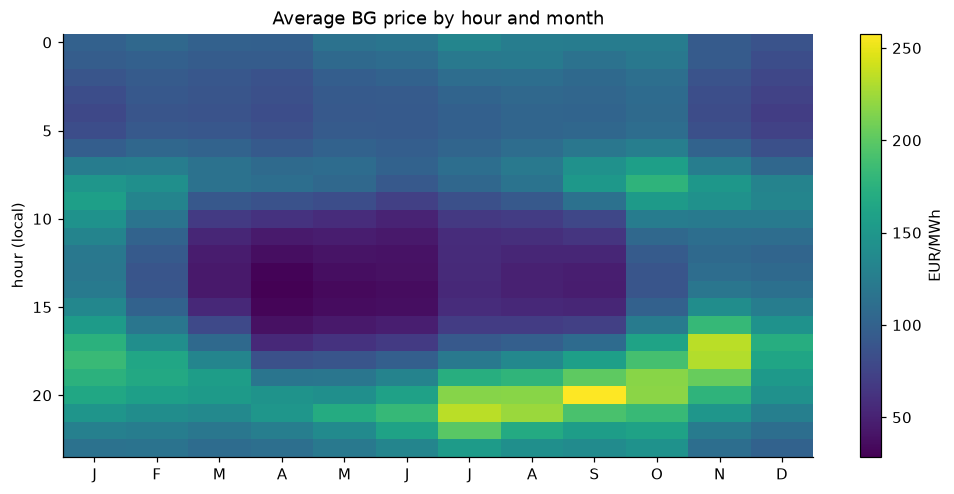

Takeaway: cheapest hour 13:00 (66), dearest 20:00 (181); in May-Aug the midday trough is 44 vs evening peak 202 EUR/MWh.


In [2]:
hm = p.groupby([h.index.hour, h.index.month]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(hm, aspect="auto", cmap="viridis"); plt.colorbar(im, label="EUR/MWh")
ax.set_xticks(range(12), ["J","F","M","A","M","J","J","A","S","O","N","D"]); ax.set_ylabel("hour (local)")
ax.set_title("Average BG price by hour and month"); ax.grid(False); plt.show()
prof = p.groupby(h.index.hour).mean(); summer = hm[[5, 6, 7, 8]].mean(axis=1)
print(f"Takeaway: cheapest hour {prof.idxmin()}:00 ({prof.min():.0f}), dearest {prof.idxmax()}:00 ({prof.max():.0f}); "
      f"in May-Aug the midday trough is {summer.min():.0f} vs evening peak {summer.max():.0f} EUR/MWh.")

**So what:** the intraday shape (cheap midday, expensive evening ramp) is the core of any battery or demand-shifting business case, and the evening ramp is where hedging matters most.

## 2. Residual load vs price
Residual load = load − wind − solar (day-ahead forecasts).

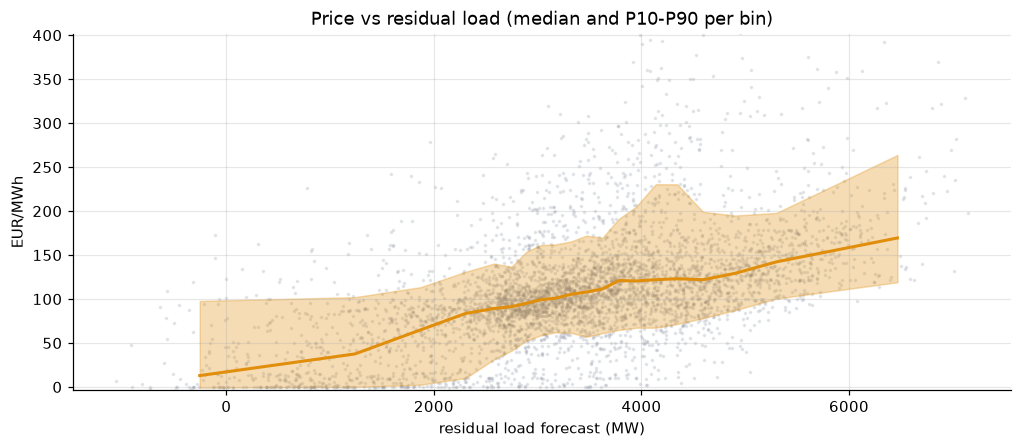

Takeaway: Spearman rho = 0.57; median price rises from 13 in the lowest to 169 EUR/MWh in the highest residual-load bin.


In [3]:
x = h[["residual_load_forecast", "price_BG"]].dropna()
b = pd.qcut(x.residual_load_forecast, 20)
g = x.groupby(b, observed=True).price_BG.agg(["median", lambda s: s.quantile(.1), lambda s: s.quantile(.9)])
mid = [i.mid for i in g.index]
plt.scatter(x.residual_load_forecast[::7], x.price_BG[::7], s=2, alpha=.15, color=GREY)
plt.fill_between(mid, g.iloc[:, 1], g.iloc[:, 2], alpha=.3, color=ACC); plt.plot(mid, g["median"], color=ACC, lw=2)
plt.ylim(x.price_BG.quantile(.005), x.price_BG.quantile(.995)); plt.xlabel("residual load forecast (MW)"); plt.ylabel("EUR/MWh")
plt.title("Price vs residual load (median and P10-P90 per bin)"); plt.show()
rho = x.corr("spearman").iloc[0, 1]
print(f"Takeaway: Spearman rho = {rho:.2f}; median price rises from {g['median'].iloc[0]:.0f} in the lowest to "
      f"{g['median'].iloc[-1]:.0f} EUR/MWh in the highest residual-load bin.")

**So what:** residual load is the single most informative fundamental; a good residual-load view is a good price view.

## 3. Generation mix over time, cheap vs expensive hours
(Actual generation — analysis only, never a feature.)

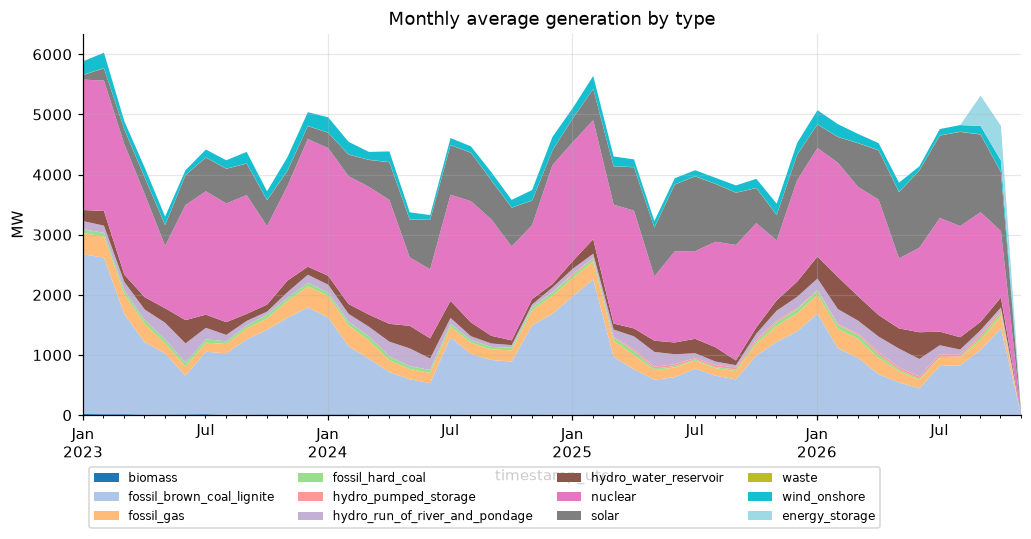

,cheapest 10%,dearest 10%,difference
gen_solar,"1,431.00",415.00,"-1,016.00"
gen_nuclear,"1,755.00","1,629.00",-126.00
gen_wind_onshore,140.00,133.00,-6.00
gen_waste,3.00,3.00,0.00
gen_biomass,16.00,17.00,1.00
gen_fossil_hard_coal,46.00,49.00,3.00
gen_hydro_run_of_river_and_pondage,114.00,142.00,29.00
gen_fossil_gas,197.00,232.00,35.00
gen_hydro_pumped_storage,0.00,53.00,53.00
gen_hydro_water_reservoir,58.00,456.00,398.00


Takeaway: in the dearest hours fossil_brown_coal_lignite is +785 MW and solar -1016 MW compared with the cheapest hours.


In [4]:
gen = [c for c in h if c.startswith("gen_")]
h[gen].resample("MS").mean().rename(columns=lambda c: c[4:]).plot.area(figsize=(11, 4.5), lw=0, cmap="tab20")
plt.ylabel("MW"); plt.title("Monthly average generation by type"); plt.legend(ncol=4, fontsize=8, loc="upper left", bbox_to_anchor=(0, -0.12)); plt.show()
lo, hi = p.quantile([.1, .9])
cmp = pd.DataFrame({"cheapest 10%": h.loc[p <= lo, gen].mean(), "dearest 10%": h.loc[p >= hi, gen].mean()})
cmp["difference"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]
cmp = cmp.sort_values("difference"); display(cmp.round(0))
print(f"Takeaway: in the dearest hours {cmp.index[-1][4:]} is {cmp.difference.iloc[-1]:+.0f} MW and "
      f"{cmp.index[0][4:]} {cmp.difference.iloc[0]:+.0f} MW compared with the cheapest hours.")

**So what:** flexible thermal and hydro plants are marginal in expensive hours; solar defines the floor. Outages or water levels of these plants are key information not in our data.

## 4. Volatility and extremes

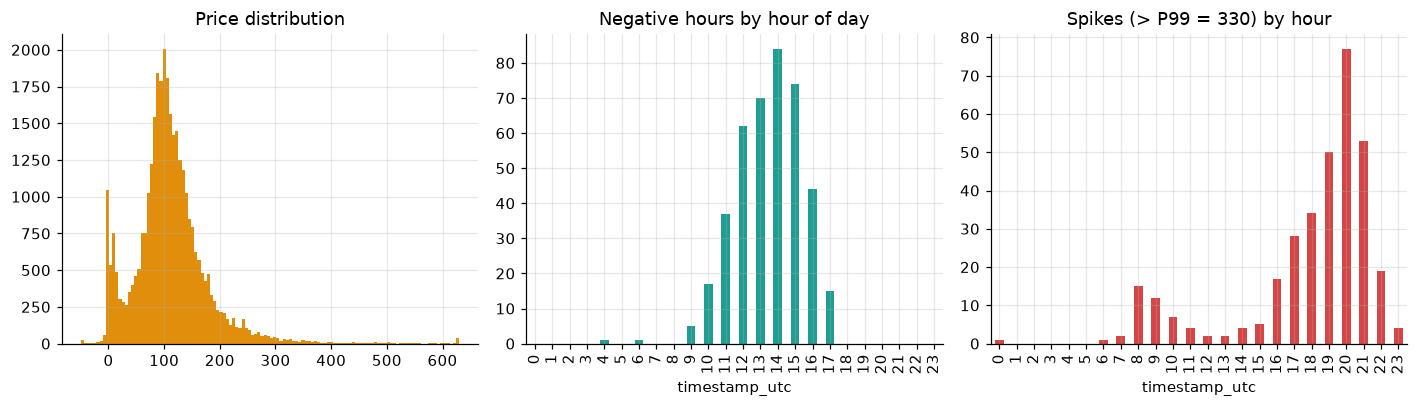

Negative hours per year: {2023: 11, 2024: 55, 2025: 170, 2026: 174}
Takeaway: 410 negative hours, concentrated at 14:00 and in month 4; spikes above 330 EUR/MWh cluster at 20:00.


In [5]:
spk = p.quantile(.99)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
p.clip(-50, p.quantile(.999)).hist(bins=120, ax=ax[0], color=ACC); ax[0].set_title("Price distribution")
neg = (p < 0).groupby(h.index.hour).sum(); neg.plot.bar(ax=ax[1], color=TEAL); ax[1].set_title("Negative hours by hour of day")
(p > spk).groupby(h.index.hour).sum().plot.bar(ax=ax[2], color=RED); ax[2].set_title(f"Spikes (> P99 = {spk:.0f}) by hour")
plt.tight_layout(); plt.show()
ny = (p < 0).groupby(h.index.year).sum(); print("Negative hours per year:", ny.to_dict())
nm = (p < 0).groupby(h.index.month).sum()
print(f"Takeaway: {int((p<0).sum())} negative hours, concentrated at {neg.idxmax()}:00 and in month {nm.idxmax()}; "
      f"spikes above {spk:.0f} EUR/MWh cluster at {(p > spk).groupby(h.index.hour).sum().idxmax()}:00.")

**So what:** negative prices are a spring/summer, sunny-weekend-midday phenomenon; spikes are an evening phenomenon. Different hours need different risk treatment.

## 5. Cross-border coupling

,mean_spread,coupled_pct,BG_higher_pct,BG_lower_pct
zone,,,,
RO,-2.19,91.15,1.60,7.25
GR,0.48,68.96,15.50,15.54
HU,-3.15,55.95,17.29,26.76


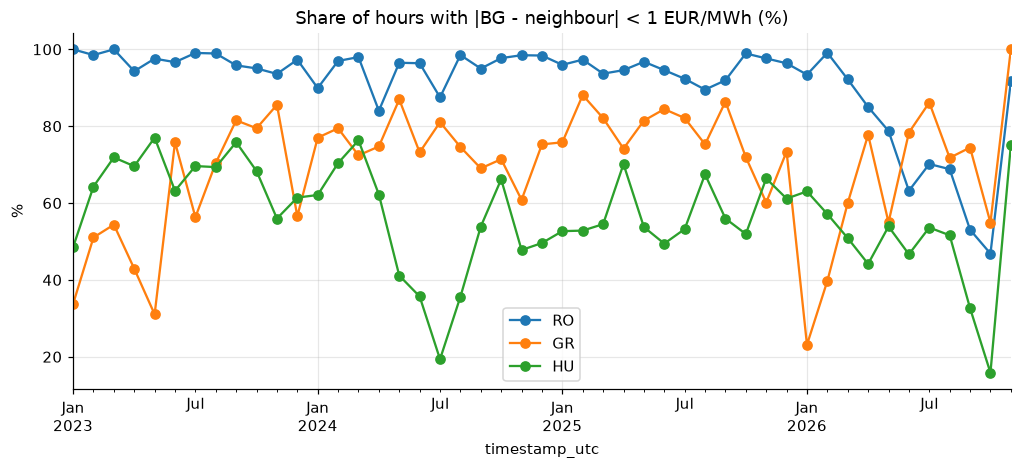

Takeaway: BG is within 1 EUR/MWh of RO in 91% of hours and of GR in 69%; BG (moving with RO) is above both GR and HU in 2% of hours and below both in 2%.
Coupling with RO by month (last 8): {'2026-04': 85.0, '2026-05': 79.0, '2026-06': 63.0, '2026-07': 70.0, '2026-08': 69.0, '2026-09': 53.0, '2026-10': 47.0, '2026-11': 92.0}


In [6]:
rows = []
for z in ["RO", "GR", "HU"]:
    s = (h.price_BG - h[f"price_{z}"]).dropna()
    rows.append(dict(zone=z, mean_spread=s.mean(), coupled_pct=100 * (s.abs() < 1).mean(),
                     BG_higher_pct=100 * (s >= 1).mean(), BG_lower_pct=100 * (s <= -1).mean()))
cb = pd.DataFrame(rows).set_index("zone"); display(cb)
cpl = pd.DataFrame({z: ((h.price_BG - h[f"price_{z}"]).abs() < 1) for z in ["RO", "GR", "HU"]}).resample("MS").mean() * 100
cpl.plot(marker="o", title="Share of hours with |BG - neighbour| < 1 EUR/MWh (%)"); plt.ylabel("%"); plt.show()
P = h[["price_BG", "price_RO", "price_GR", "price_HU"]].dropna()
gh = P[["price_GR", "price_HU"]]
top = P.price_BG >= gh.max(axis=1) + 1; low = P.price_BG <= gh.min(axis=1) - 1
print(f"Takeaway: BG is within 1 EUR/MWh of RO in {cb.loc['RO','coupled_pct']:.0f}% of hours and of GR in "
      f"{cb.loc['GR','coupled_pct']:.0f}%; BG (moving with RO) is above both GR and HU in {top.mean():.0%} of hours and below both in {low.mean():.0%}.")
print("Coupling with RO by month (last 8):", {k.strftime("%Y-%m"): v for k, v in cpl["RO"].tail(8).round(0).items()})

*Note on the definition:* since mid-2026 BG and RO prices in clearly coupled hours differ by a few cents (e.g. 161.82 vs 161.79 EUR/MWh), so an exact-equality test understates convergence. Coupling is therefore defined as |spread| < 1 EUR/MWh. Even with this tolerance, decoupling increases strongly in 2026.

**So what:** most of the time BG imports the regional price; decoupled hours (congested interconnectors) are where local fundamentals matter and where cross-border spread trades live.

## 6. Daily spread (max − min) by season

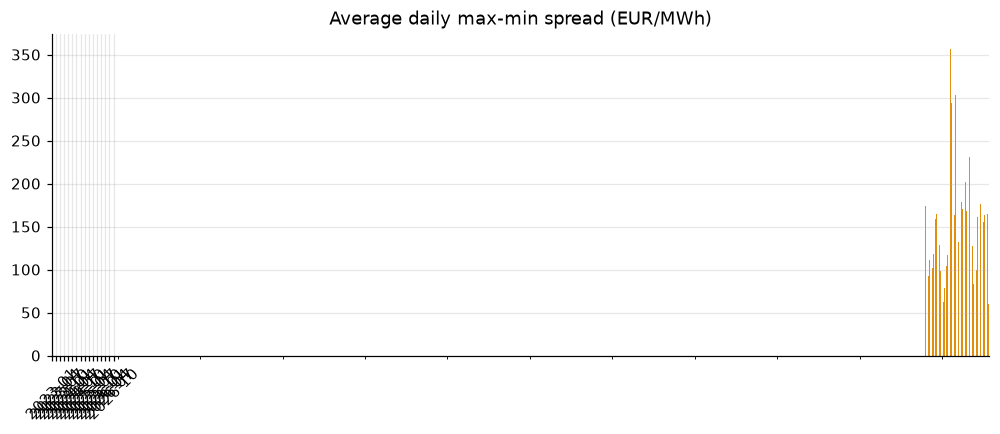

Takeaway: the daily spread averages 158 EUR/MWh, highest in month 9 (229) and lowest in month 2 (105); latest-year average 157 vs first-year 126.


In [7]:
ds = p.groupby(h.index.date).agg(lambda s: s.max() - s.min()); ds.index = pd.to_datetime(ds.index)
ds.resample("MS").mean().plot.bar(color=ACC, figsize=(11, 3.8), title="Average daily max-min spread (EUR/MWh)")
plt.xticks(range(0, len(ds.resample("MS").mean()), 3), [d.strftime("%Y-%m") for d in ds.resample("MS").mean().index[::3]], rotation=45); plt.show()
season = ds.groupby(ds.index.month).mean()
print(f"Takeaway: the daily spread averages {ds.mean():.0f} EUR/MWh, highest in month {season.idxmax()} "
      f"({season.max():.0f}) and lowest in month {season.idxmin()} ({season.min():.0f}); latest-year average "
      f"{ds[ds.index.year == ds.index.year.max()].mean():.0f} vs first-year {ds[ds.index.year == ds.index.year.min()].mean():.0f}.")

**So what:** the daily spread is the battery's raw revenue pool — notebook 05 turns it into EUR/MW-year.